In [13]:
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from random import random
import matplotlib.pyplot as plt
import matplotlib.ticker as plticker

# Personalización de parámetros para todas las gráficas
plt.rcParams["figure.figsize"] = [16, 5]
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.bottom"] = False
plt.rcParams["axes.spines.left"] = False
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["xtick.labelsize"] = 15
plt.rcParams["ytick.labelsize"] = 15
plt.rcParams["lines.markerfacecolor"] = "purple"
plt.rcParams["lines.markeredgecolor"] = "purple"
plt.rcParams["lines.markersize"] = 6
plt.rcParams["patch.facecolor"] = "purple"
plt.rcParams["patch.edgecolor"] = "purple"

<h2 style="color:violet">Series de tiempo de Pasajeros con Estacionalidad</h2>

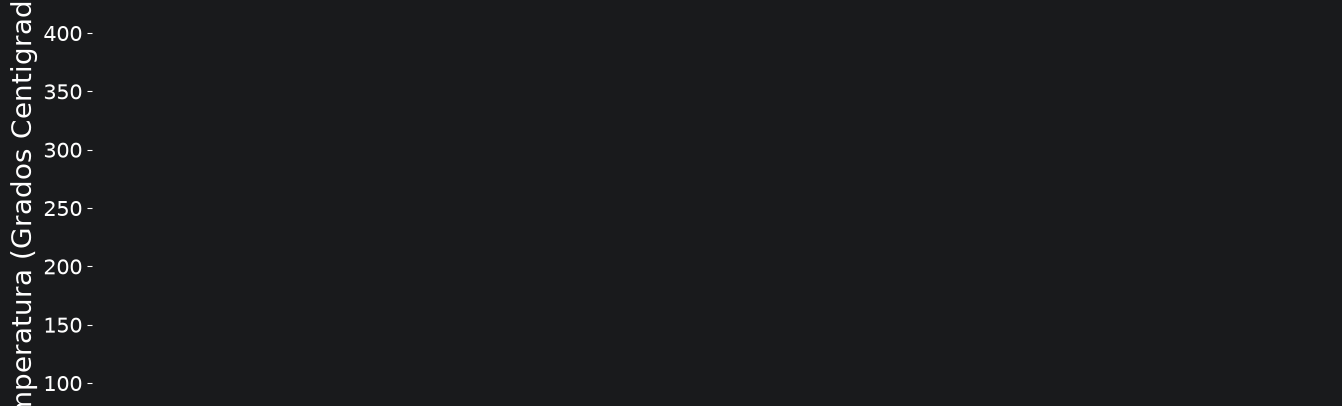

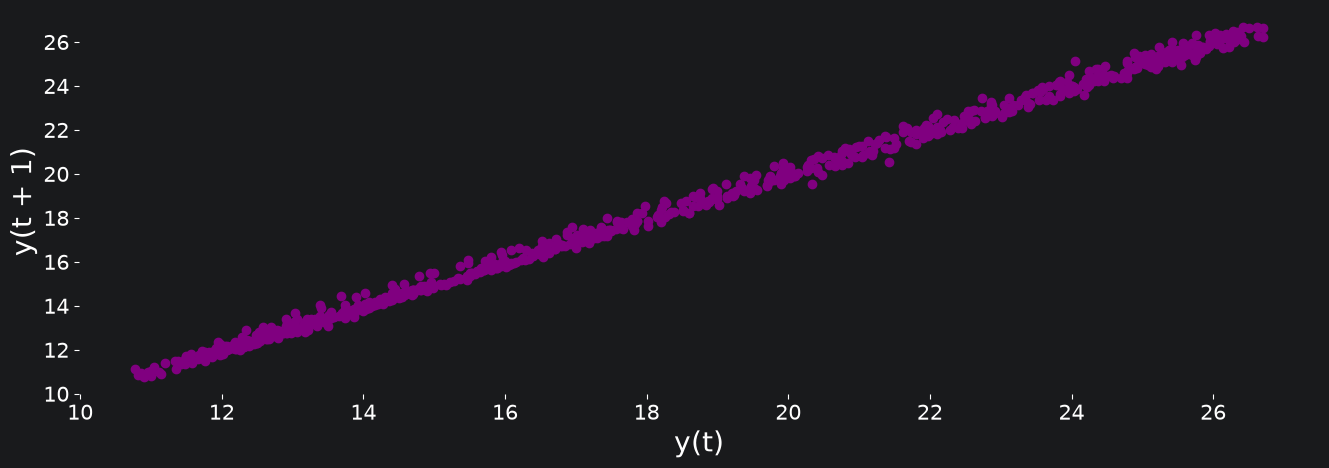

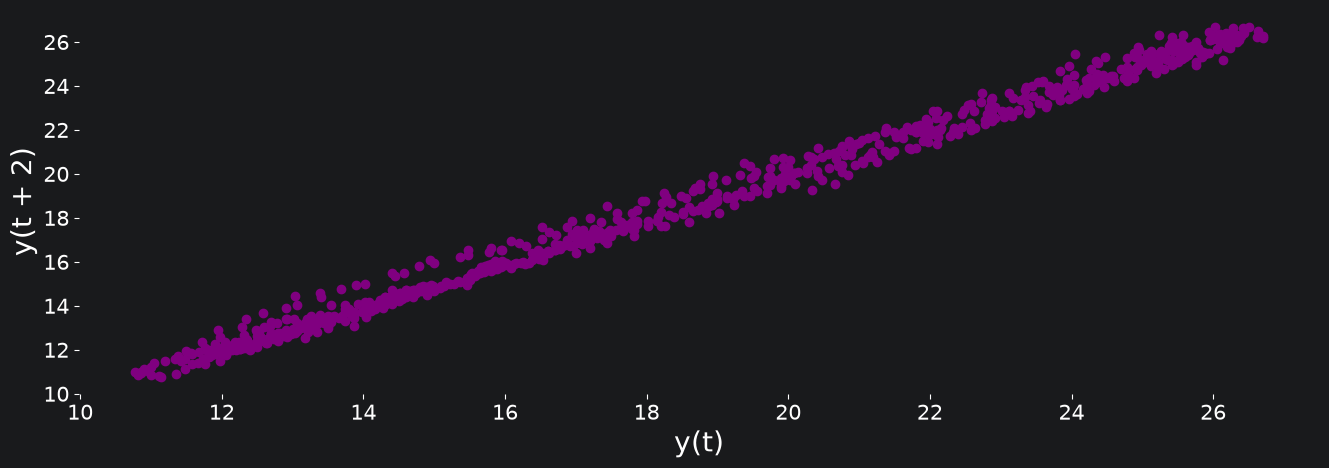

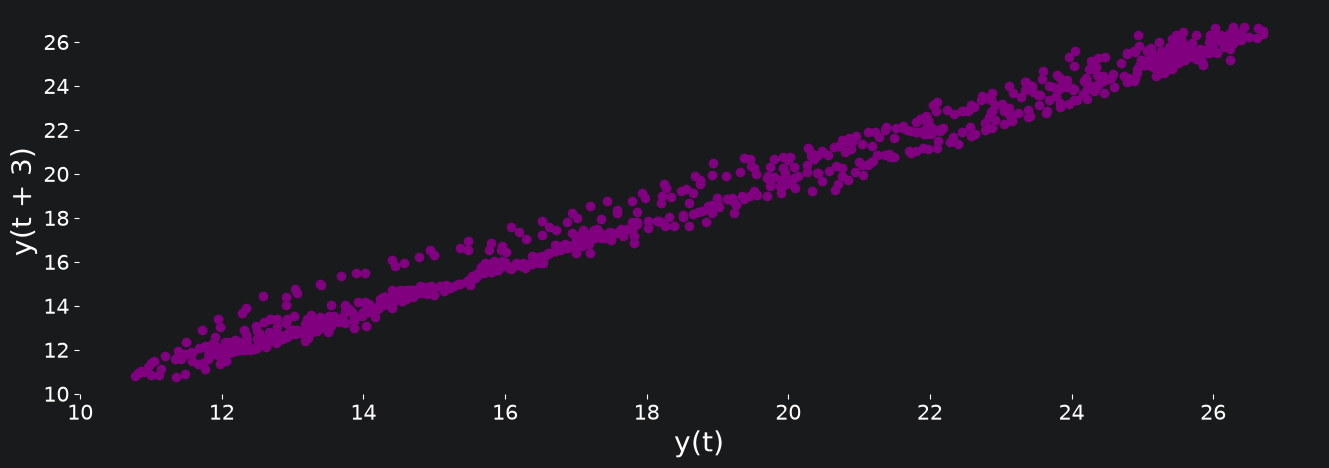

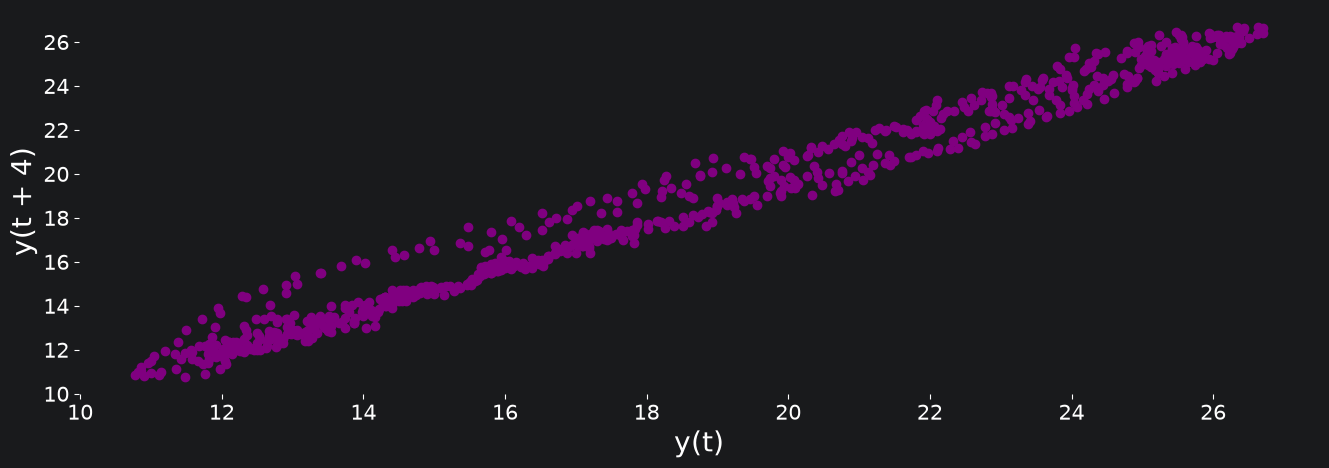

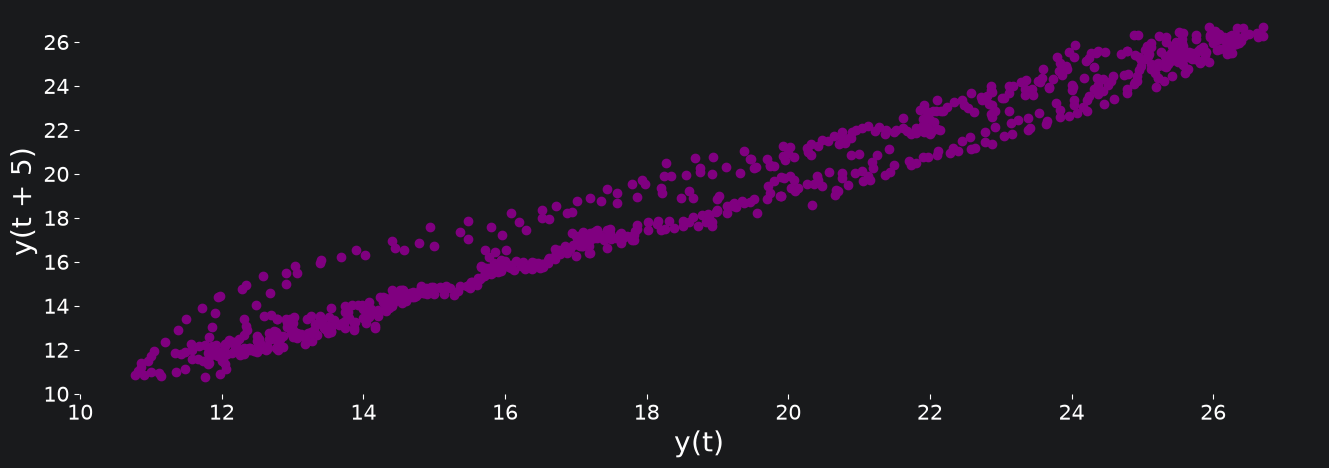

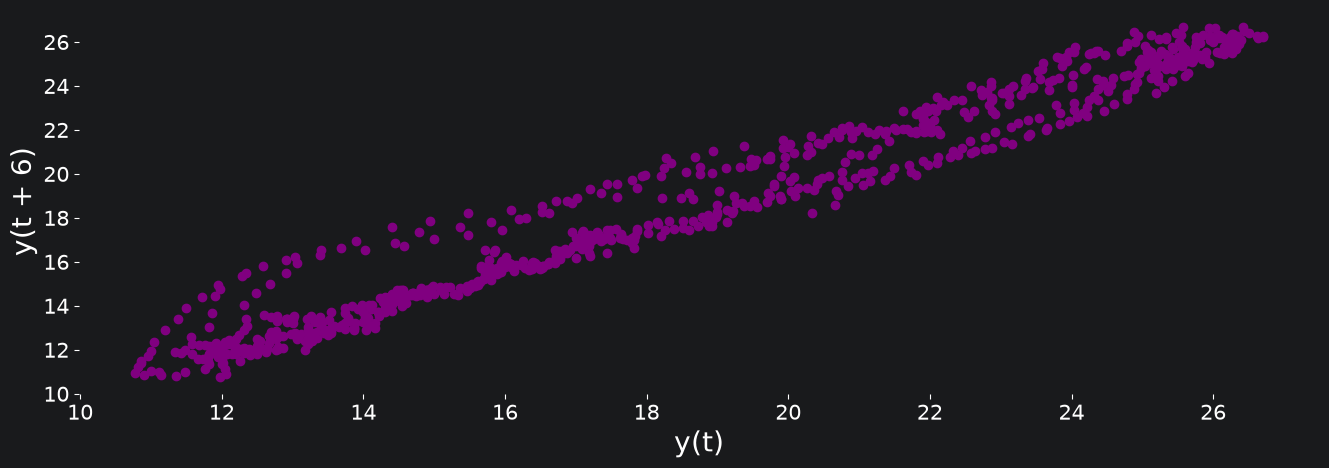

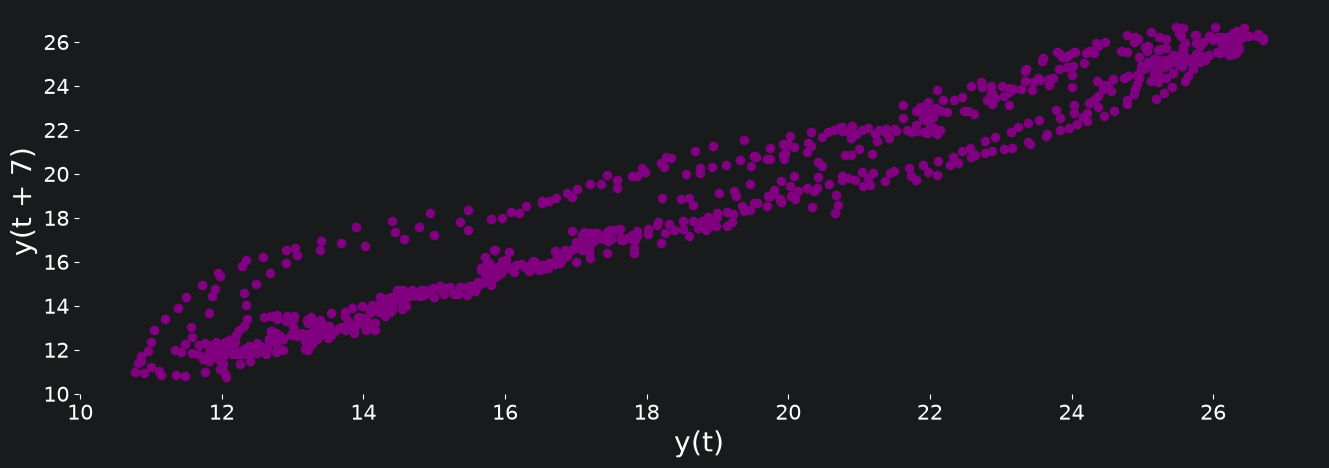

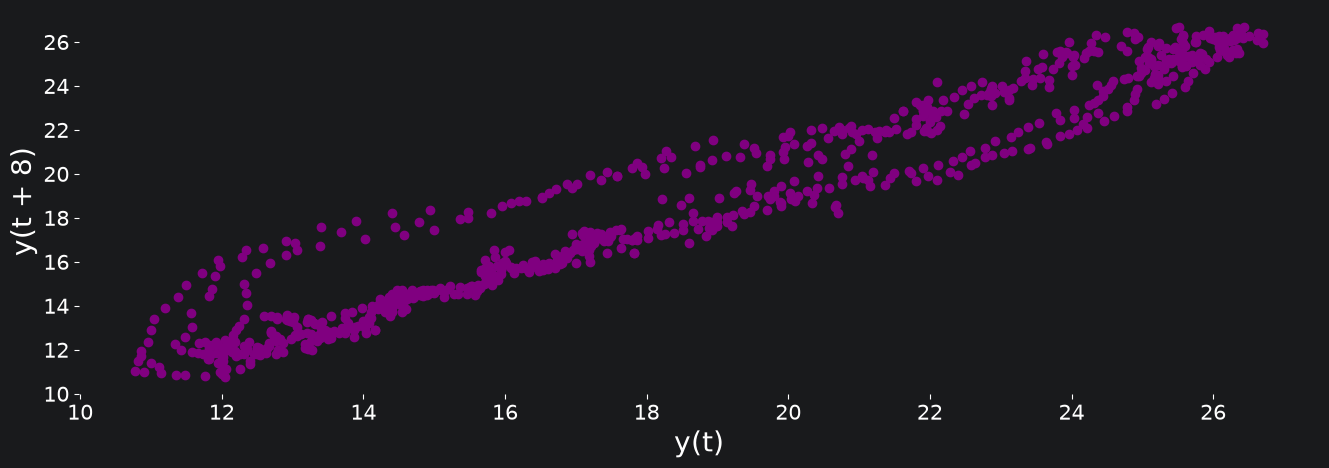

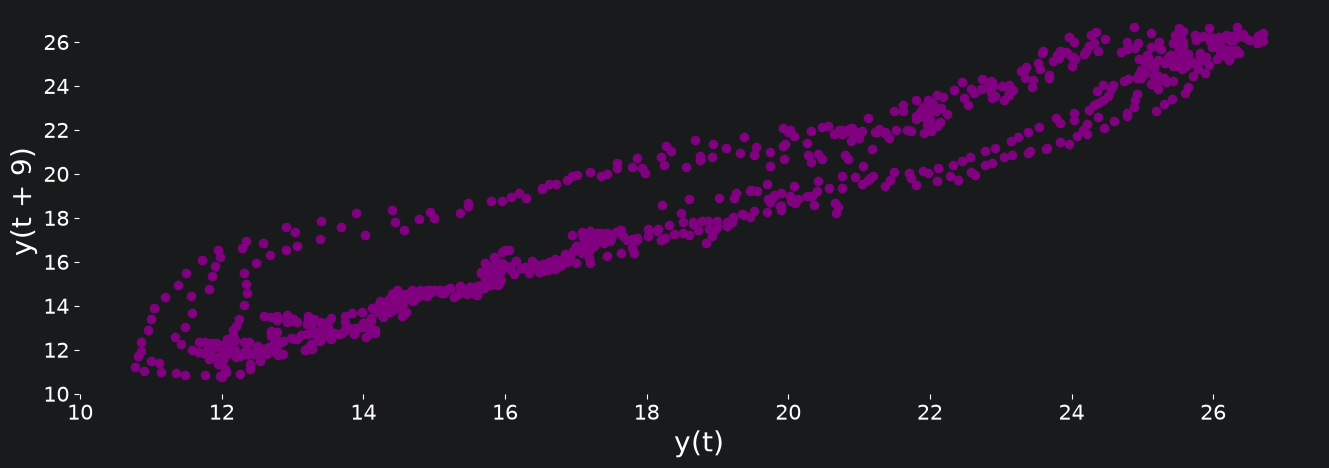

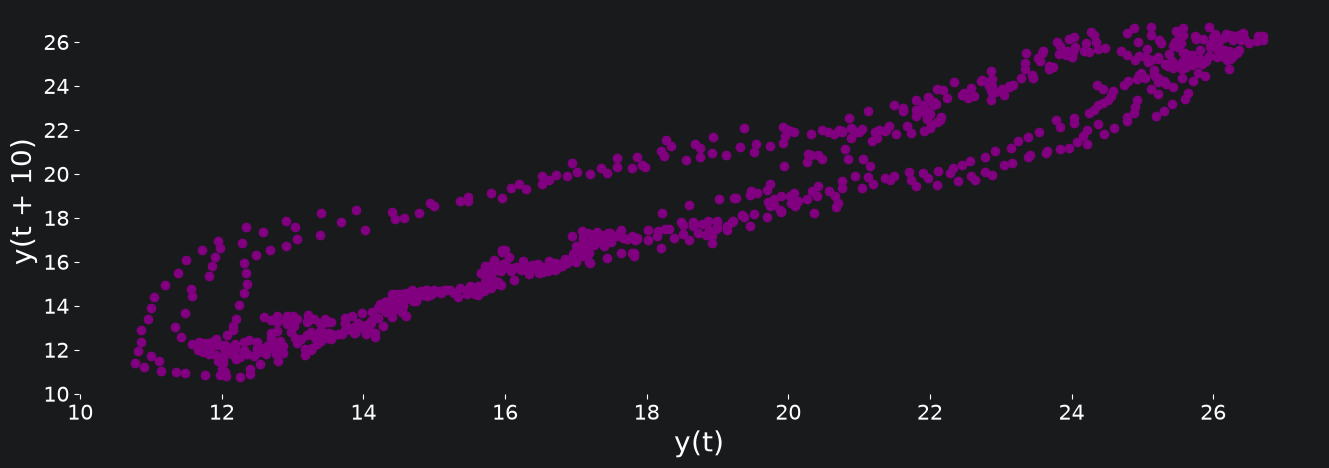

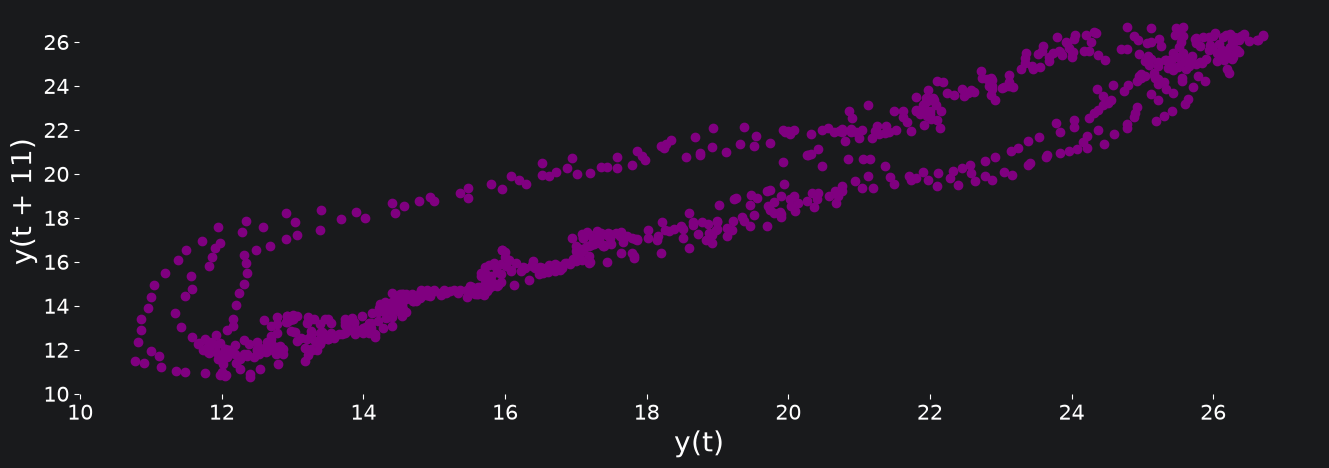

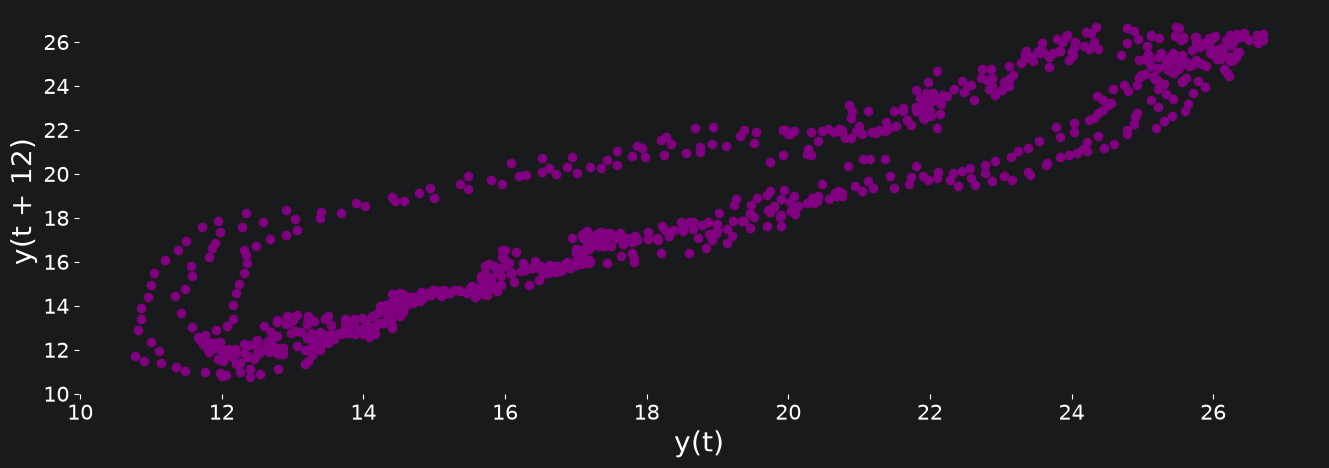

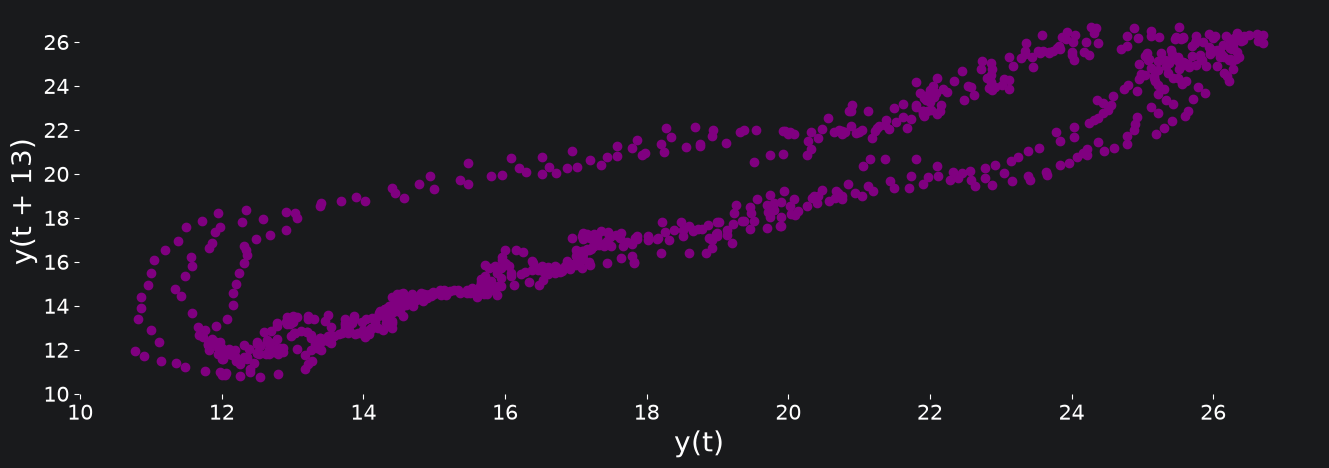

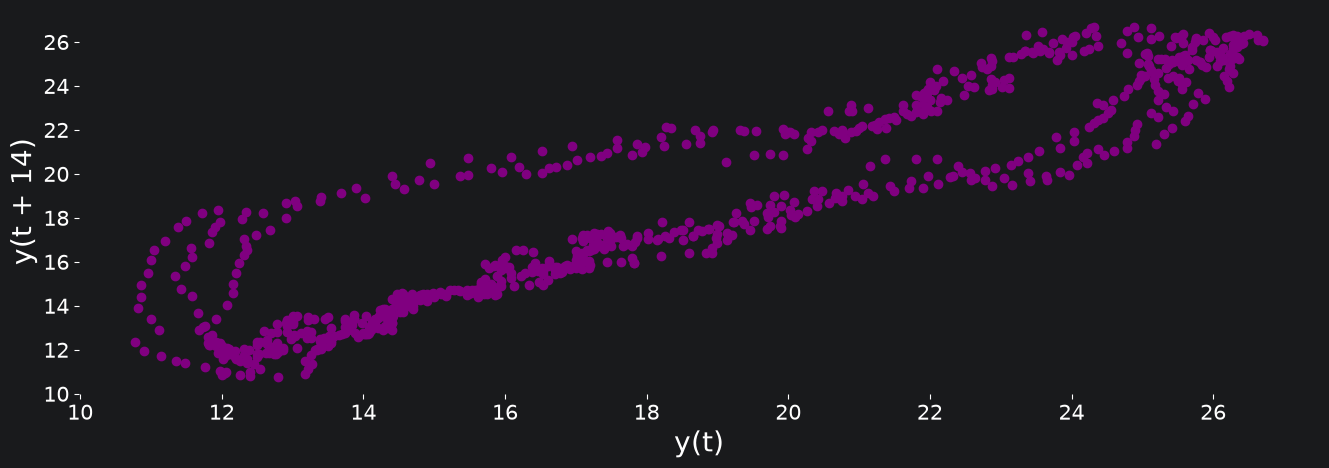

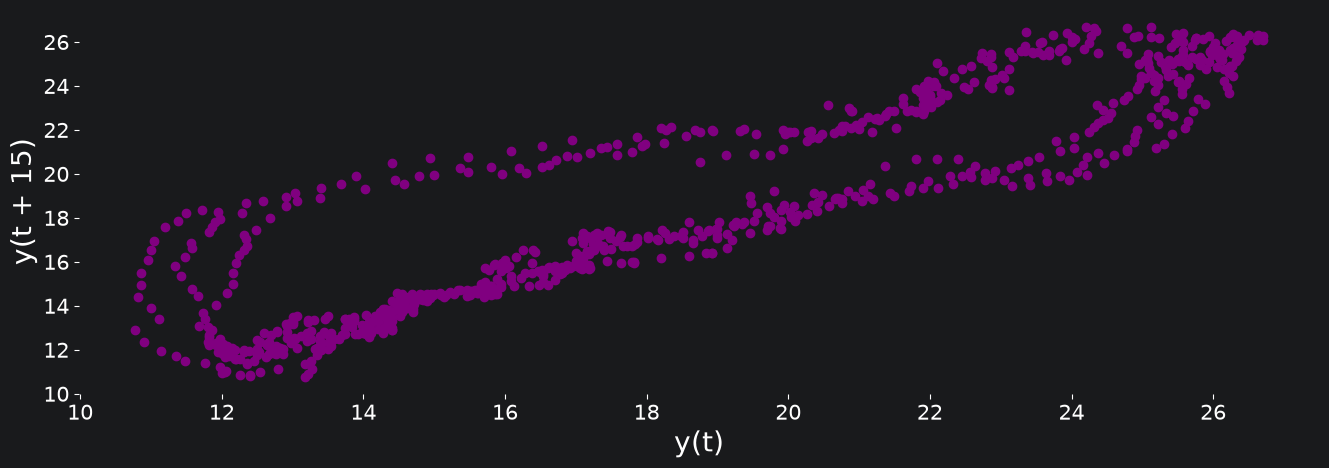

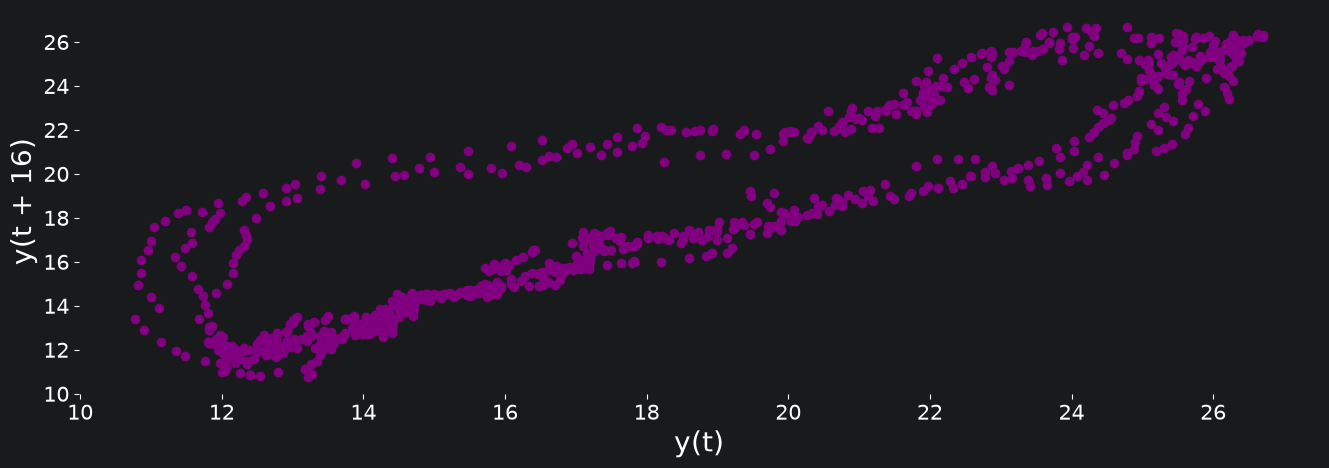

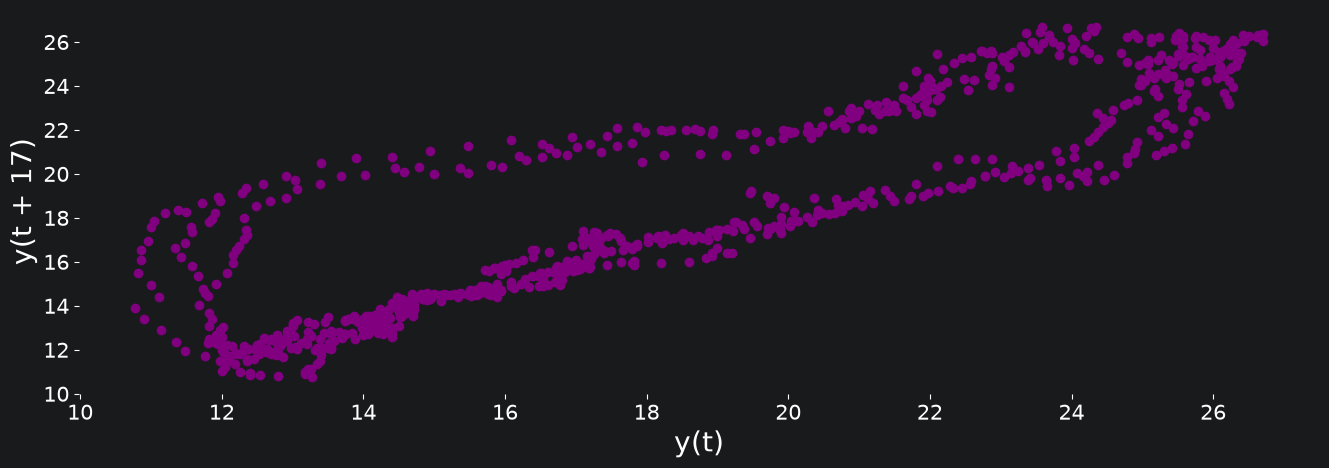

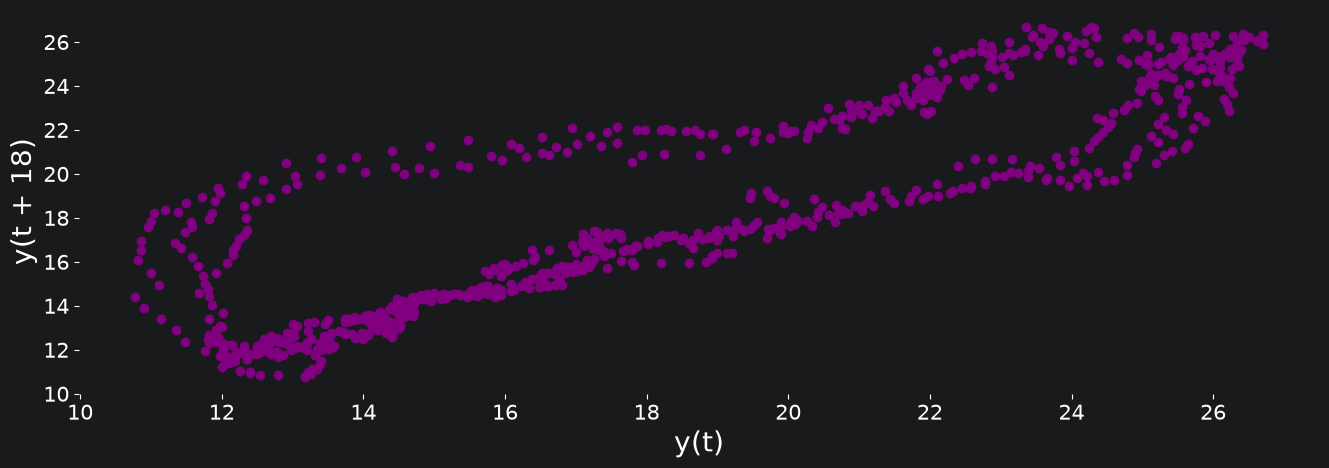

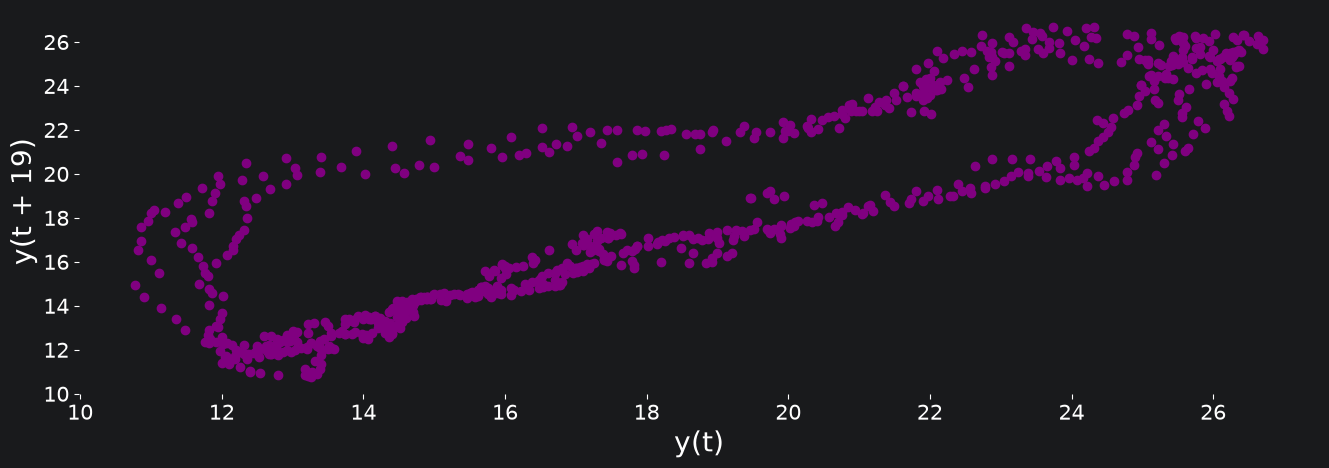

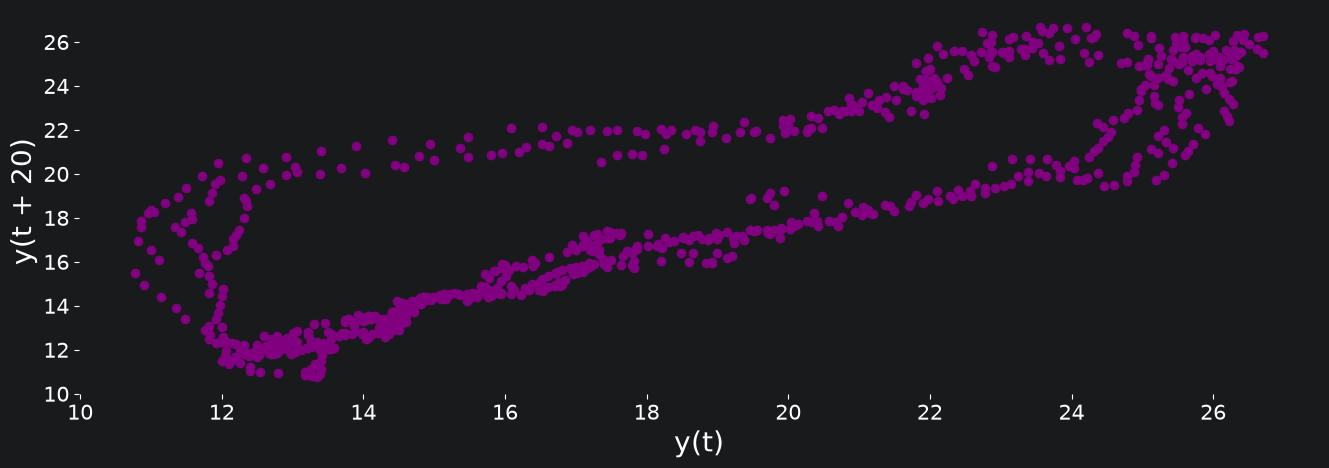

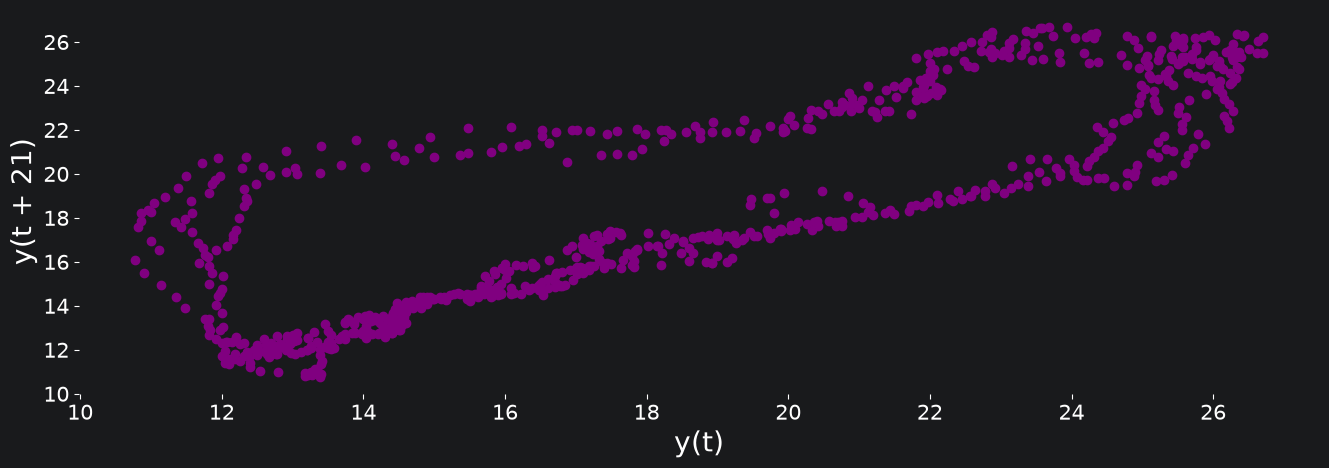

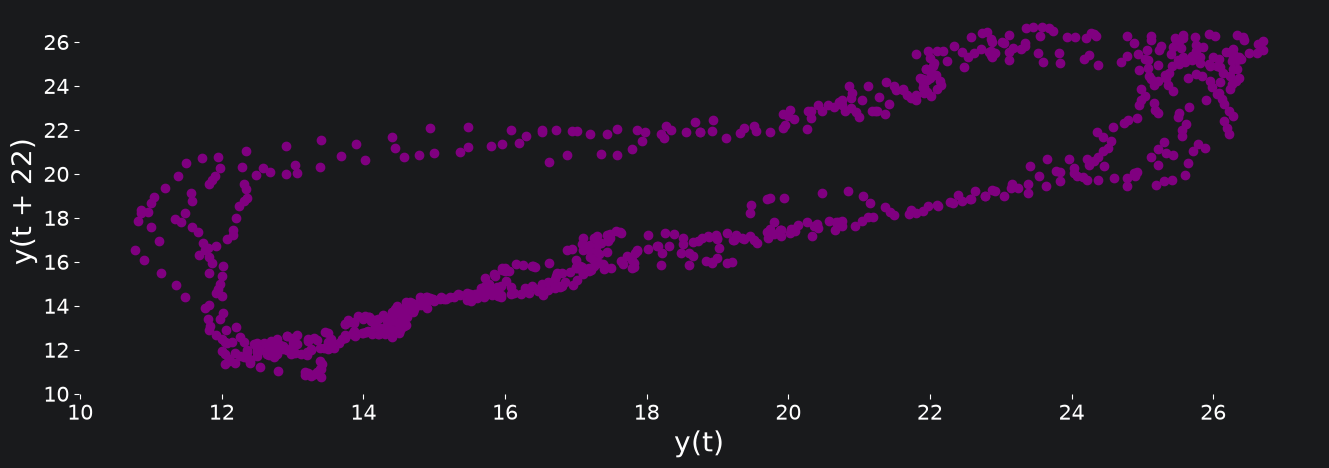

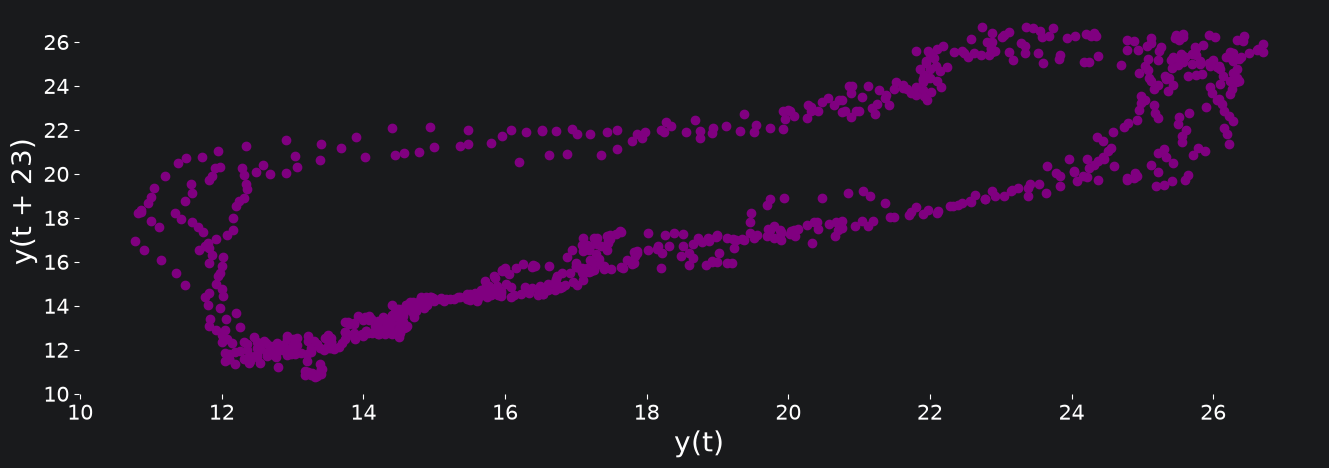

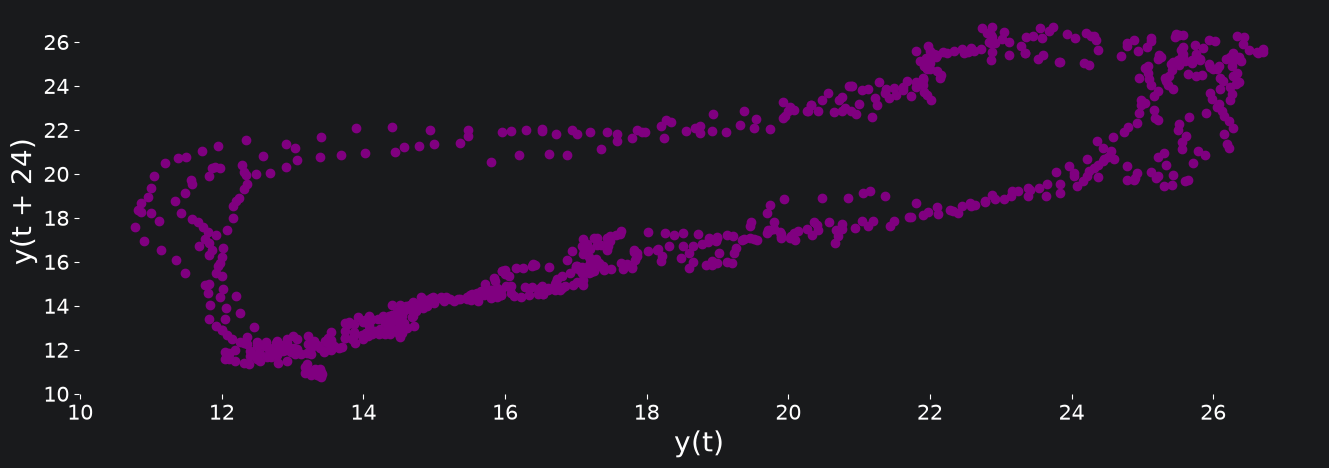

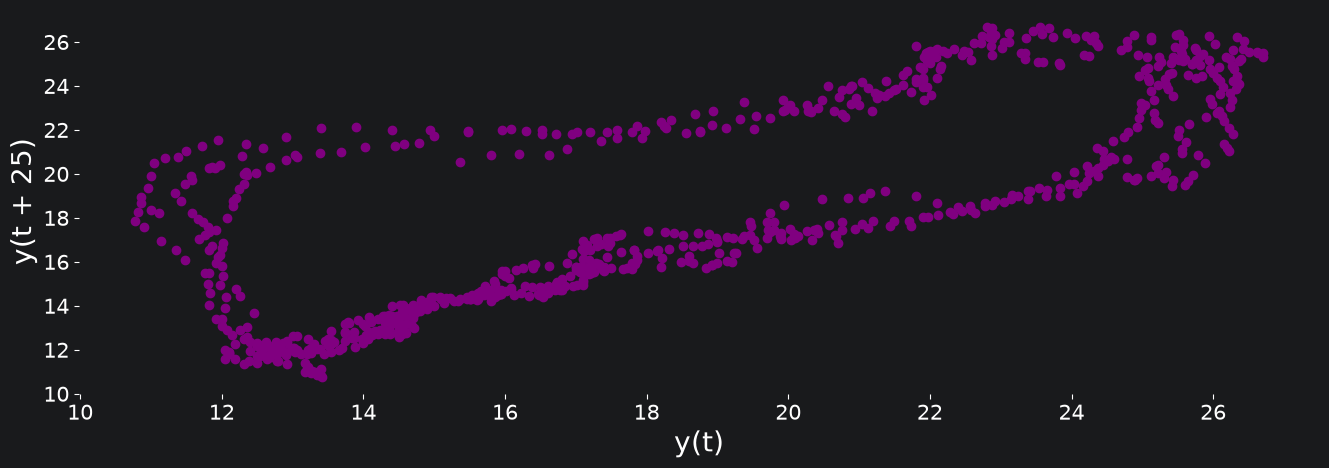

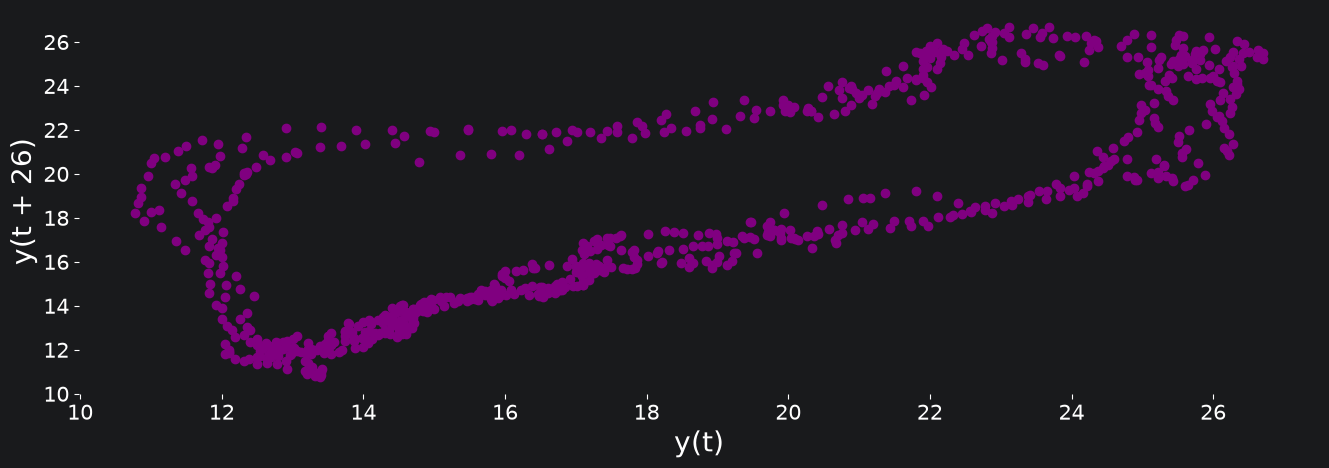

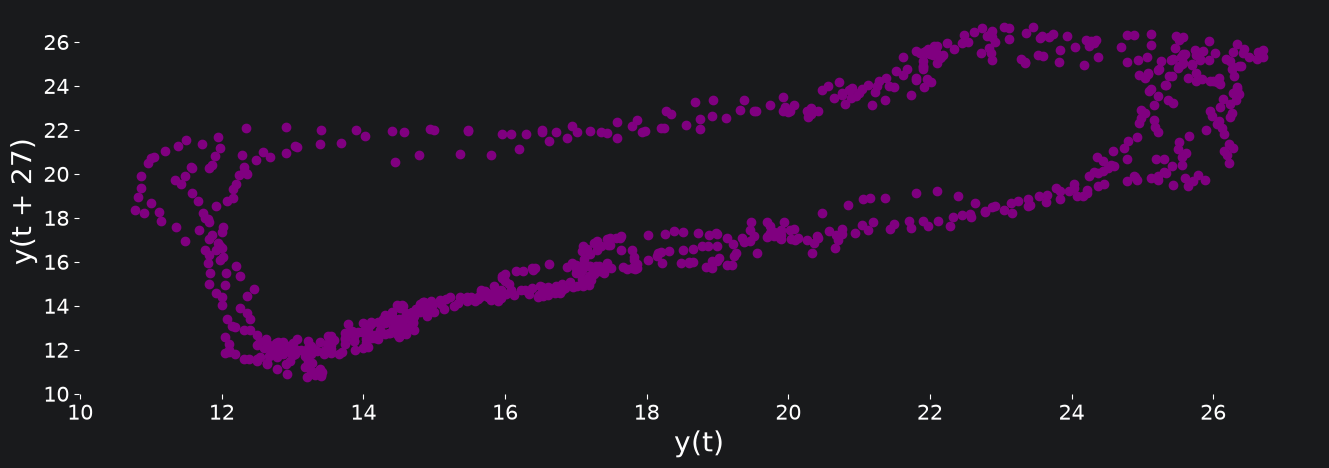

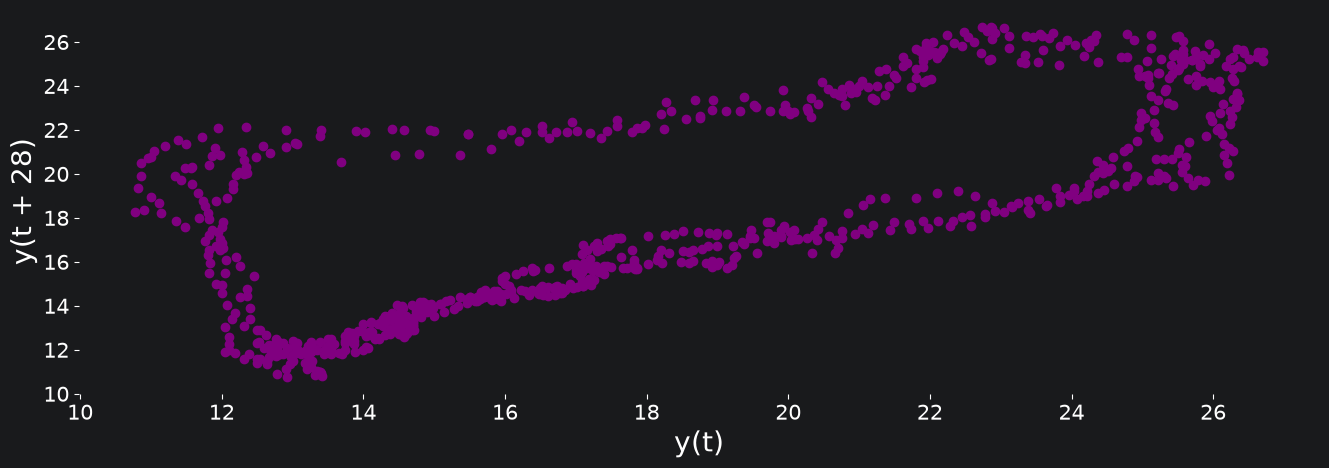

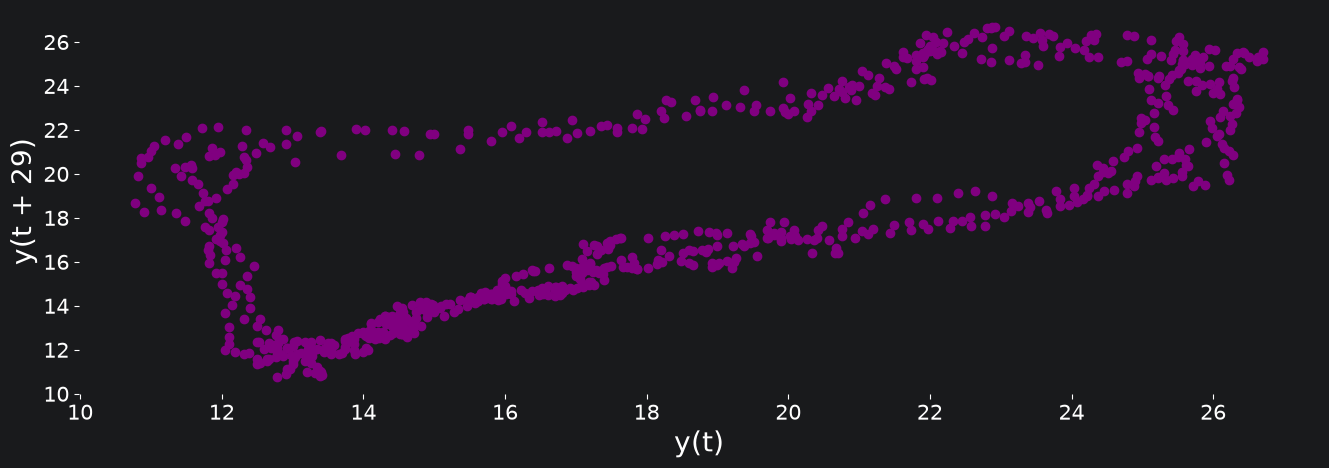

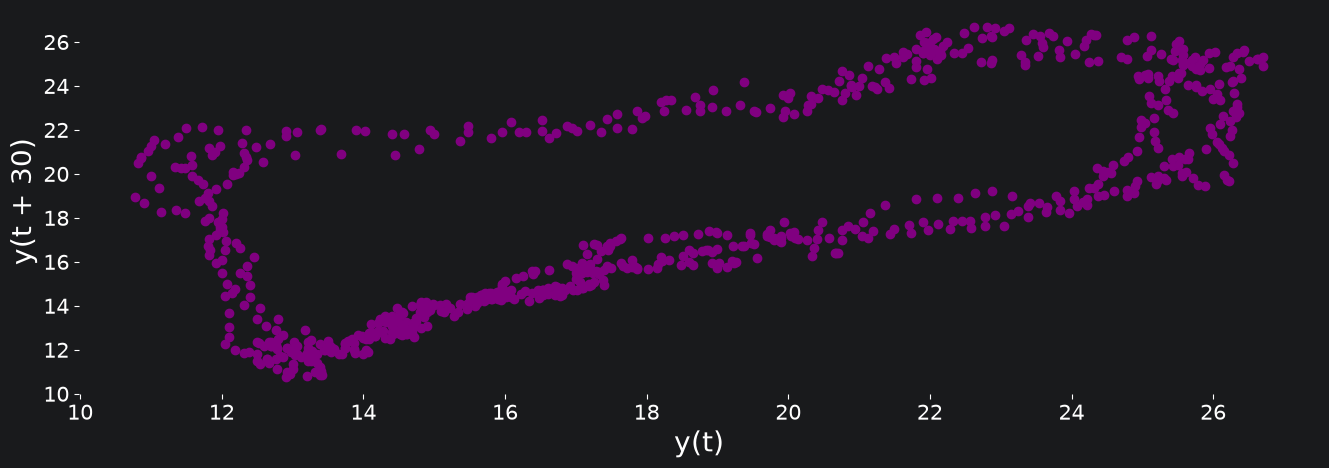

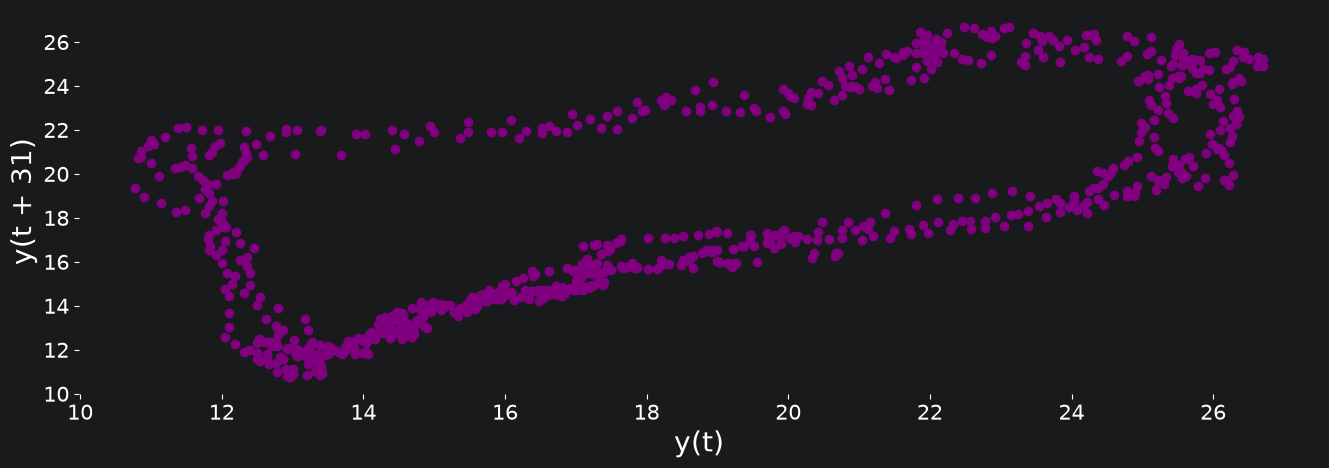

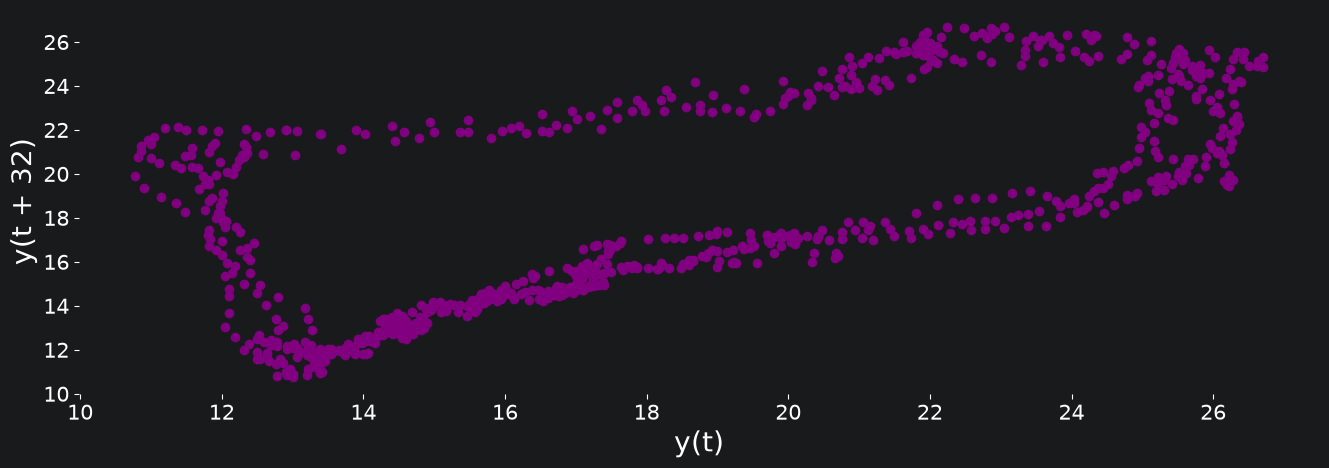

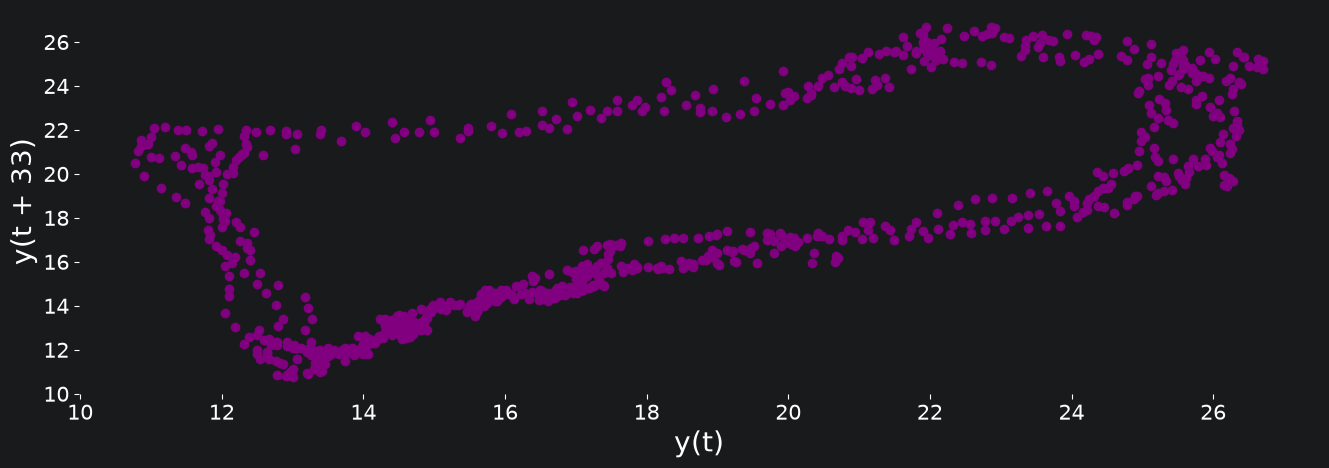

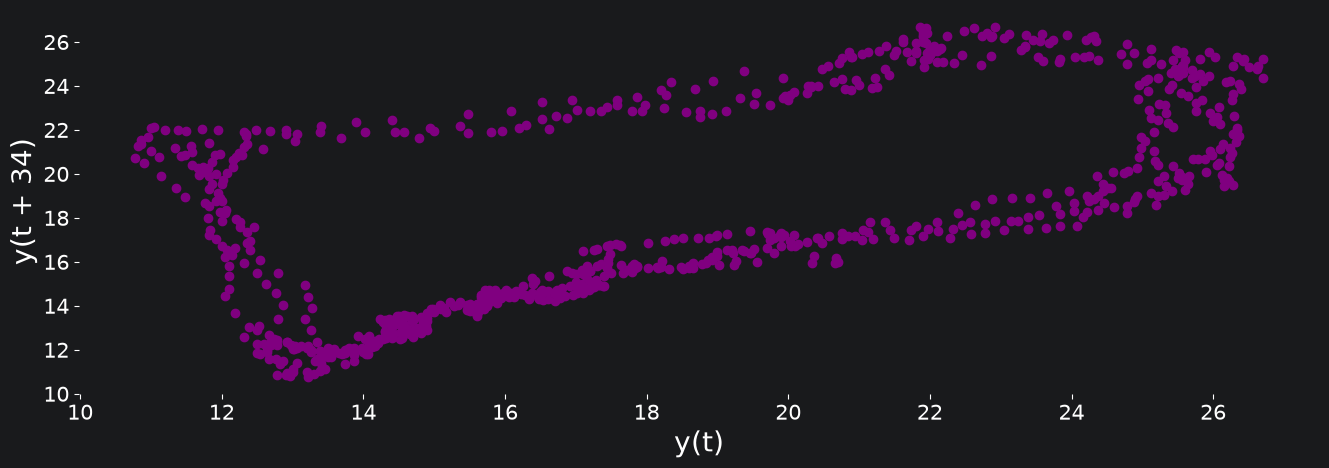

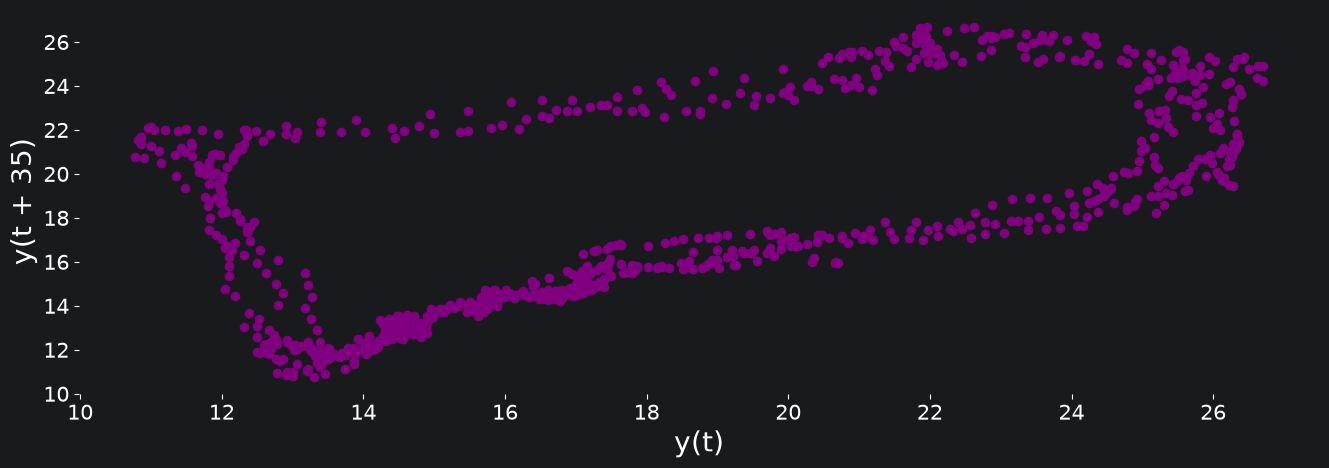

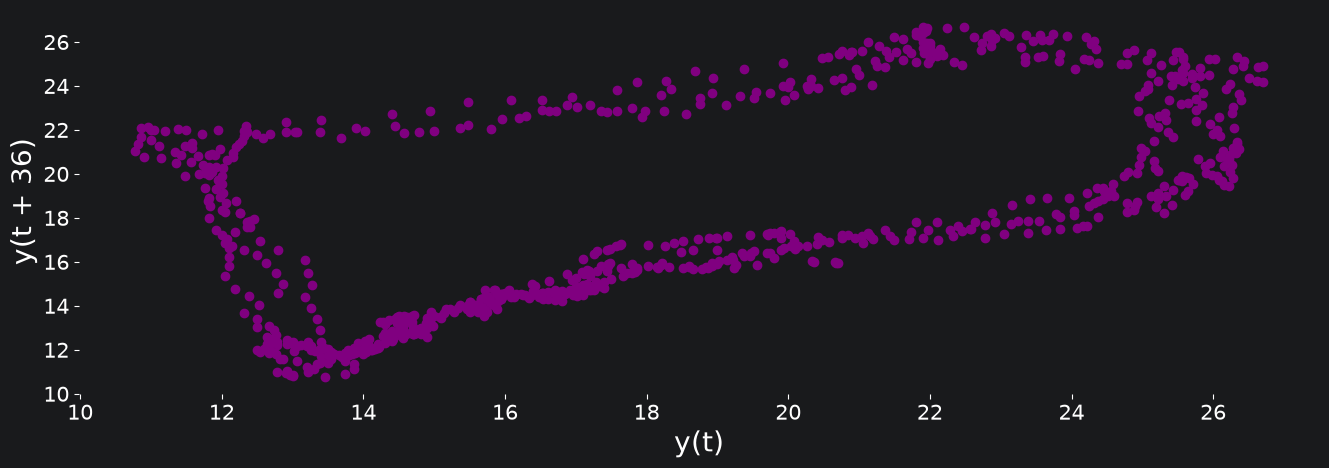

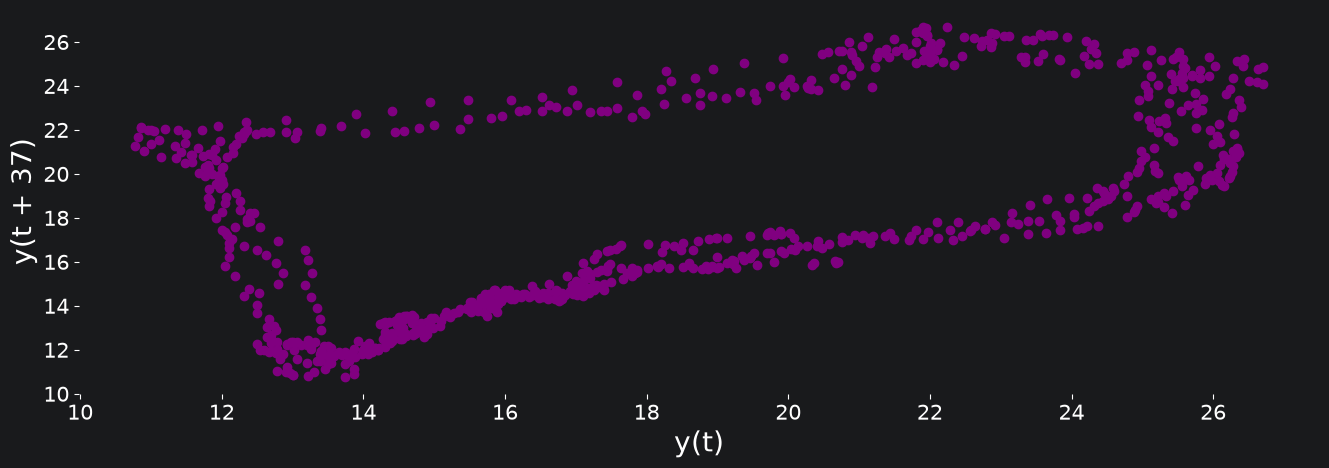

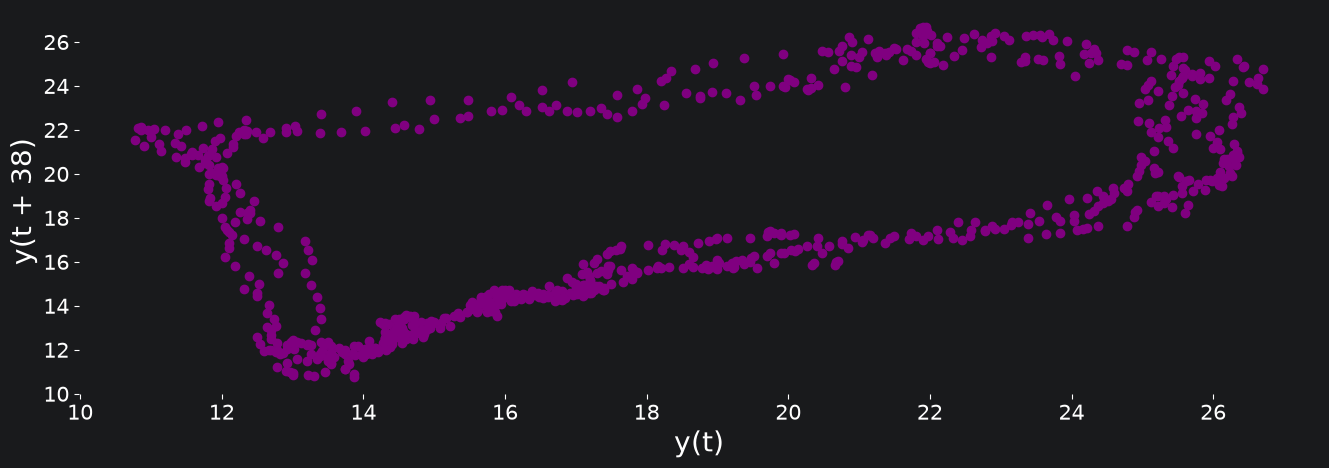

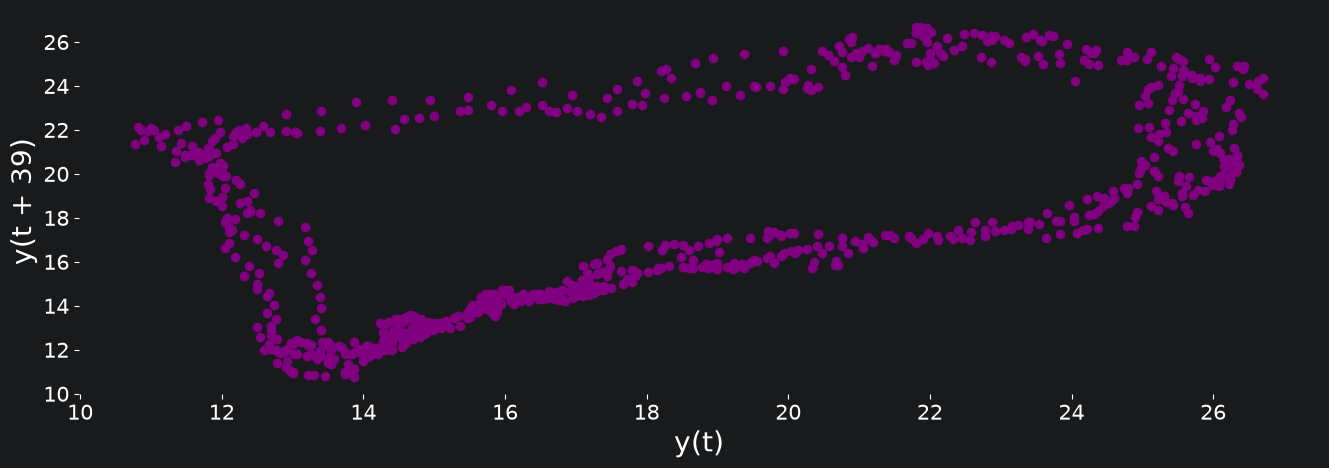

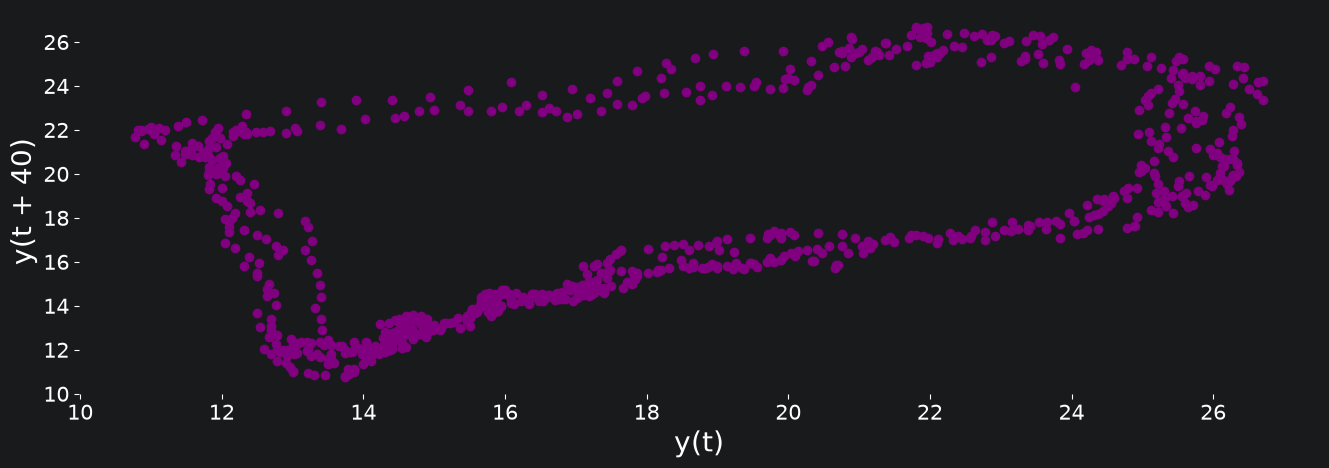

KeyboardInterrupt: 

In [14]:
# Cargando datos
datos = pd.read_csv("../data/datos_clima.csv")

datos["datetime"] = pd.to_datetime(datos["datetime"], dayfirst=True)

datos = datos[["datetime", "T"]].set_index(["datetime"])

# Resampling
datos = datos.groupby(datos.index).mean()
datos = datos.resample('5min').mean()

len(f"Datos {datos}")

datos.to_csv("datos_clima_5min.csv")

# Gráfica de la serie de tiempo
fig, ax = plt.subplots()
ax.set_ylim([90, 420])
ax.xaxis.set_major_locator(plticker.MultipleLocator(base=10))
ax.plot(datos.index, datos["T"],
        color="pink", marker="o", linestyle="-")
ax.bar(datos.index, datos["T"],
       width=0.1, color="pink", alpha=0.7)
ax.set_ylabel("Temperatura (Grados Centigrados)")
plt.show()

# Gráficas de retardo
for retraso in range(1, 60):
    pd.plotting.lag_plot(datos["T"], lag = retraso)
    plt.show()

# Gráfica de la función de autocorrelación
plot_acf(datos, lags=99, alpha=None)
plt.ylabel("Coeficiente de Autocorrelación")
plt.title("")
plt.xlabel("Retardo")
plt.show()